# Model Evaluation and Hyperparameter Tuning

Models from the training notebook are evaluated using suitable metrics, like precision, recall, F1, confusion matrices, etc.

GridSearchCV is used to tune the logistic regression, decision tree and random forest models


## 1. Import the required libraries

These libraries are used to load the saved models, calculate evaluation metrics, display confusion matrices and perform hyperparameter tuning.

In [29]:
import pandas as pd
import joblib
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import roc_auc_score, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

## 2. Load models and data


In [30]:
model_data = joblib.load("data/processed/trained_models.joblib")
prep_data = joblib.load("data/processed/prepared_data.joblib")

X_train = prep_data["X_train"]
y_train = prep_data["y_train"]
X_test = model_data["X_test"]
y_test = model_data["y_test"]
models = model_data["models"]
cv_results = model_data["cv_results"]

## 3. Create evaluation function

This function calculates all relevant scores/metrics to the models and creates a confusion matrix

In [31]:
def evaluate_model(model, X_test, y_test):
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions, zero_division=0)
    recall = recall_score(y_test, predictions, zero_division=0)
    f1 = f1_score(y_test, predictions, zero_division=0)
    roc_auc = roc_auc_score(y_test, probabilities)

    print("Accuracy:", accuracy)
    print("Precision:", precision)
    print("Recall:", recall)
    print("F1 Score:", f1)
    print("ROC-AUC:", roc_auc)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        display_labels=["No Purchase", "Purchase"]
    )

    plt.show()

    return {"Accuracy": accuracy, "Precision": precision, "Recall": recall, "F1-score": f1, "ROC-AUC": roc_auc}

## 4. Evaluate models with test set


Logistic Regression
Accuracy: 0.8419437340153453
Precision: 0.4090909090909091
Recall: 0.029508196721311476
F1 Score: 0.05504587155963303
ROC-AUC: 0.7220983606557378


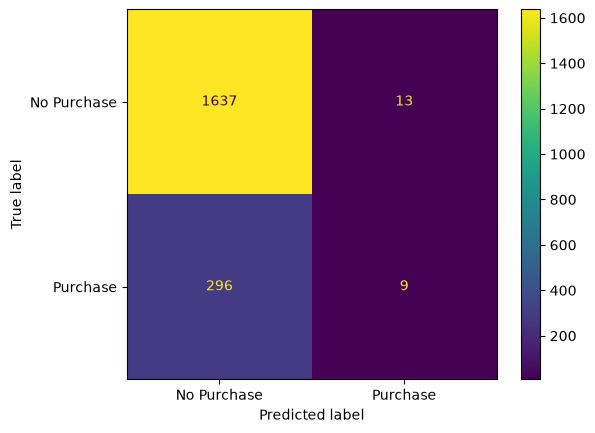

Decision Tree
Accuracy: 0.760613810741688
Precision: 0.27170868347338933
Recall: 0.3180327868852459
F1 Score: 0.2930513595166163
ROC-AUC: 0.5802285146547441


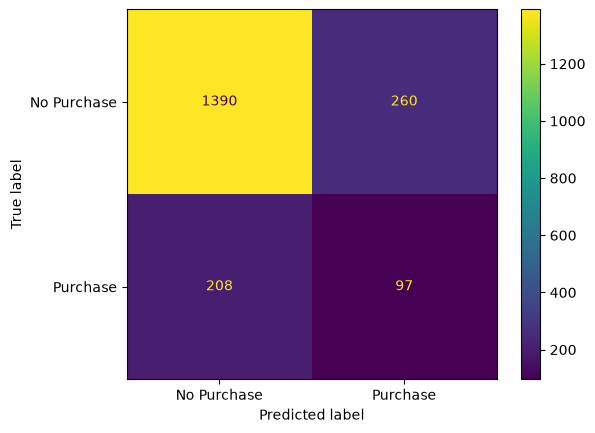

Random Forest
Accuracy: 0.8409207161125319
Precision: 0.4594594594594595
Recall: 0.11147540983606558
F1 Score: 0.17941952506596306
ROC-AUC: 0.7419761549925484


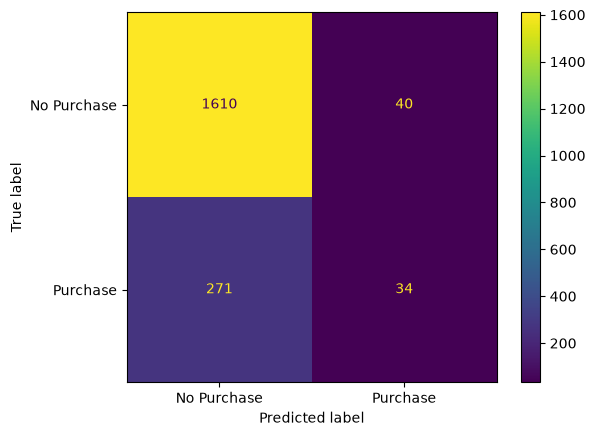

In [32]:
initial_results = {}

for name, model in models.items():
    print(name)
    initial_results[name] = evaluate_model(model, X_test, y_test)

## 5. Tune Logistic Regression

Class weight and strength of regularisation (C) are tuned


In [33]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=202300408)

logistic_parameters = {
    "C": [0.1, 1, 10, 100],
    "class_weight": [None, "balanced"]
}

logistic_search = GridSearchCV(
    LogisticRegression(max_iter=1000),
    logistic_parameters,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

logistic_search.fit(X_train, y_train)

print("Best parameters:", logistic_search.best_params_)
print("Best CV F1:", logistic_search.best_score_)

Best parameters: {'C': 10, 'class_weight': 'balanced'}
Best CV F1: 0.39253629987464206


## 6. Tune Decision Tree

Class weight, maximum tree depth, minimum samples needed to split a node and minimum samples in a leaf are tuned.


In [34]:
decision_parameters = {
    "max_depth": [None, 5, 10, 15, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "class_weight": [None, "balanced"]
}

decision_search = GridSearchCV(
    DecisionTreeClassifier(random_state=202300408),
    decision_parameters,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

decision_search.fit(X_train, y_train)

print("Best parameters:", decision_search.best_params_)
print("Best CV F1:", decision_search.best_score_)

Best parameters: {'class_weight': 'balanced', 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best CV F1: 0.38986148023534006


## 7. Tune Random Forest

Number of trees, maximum tree depth, minimum samples needed to split a node and class weight are tuned.


In [35]:
forest_parameters = {
    "n_estimators": [100, 200],
    "max_depth": [None, 15],
    "min_samples_split": [2, 5],
    "class_weight": [None, "balanced"]
}

forest_search = GridSearchCV(
    RandomForestClassifier(random_state=202300408, n_jobs=1),
    forest_parameters,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

forest_search.fit(X_train, y_train)

print("Best parameters:", forest_search.best_params_)
print("Best CV F1:", forest_search.best_score_)

Best parameters: {'class_weight': 'balanced', 'max_depth': 15, 'min_samples_split': 5, 'n_estimators': 200}
Best CV F1: 0.43222840564455167


## 8. Evaluate the tuned models


Tuned Logistic Regression
Accuracy: 0.6485933503836318
Precision: 0.25761421319796957
Recall: 0.6655737704918033
F1 Score: 0.37145471180237877
ROC-AUC: 0.7218499751614506


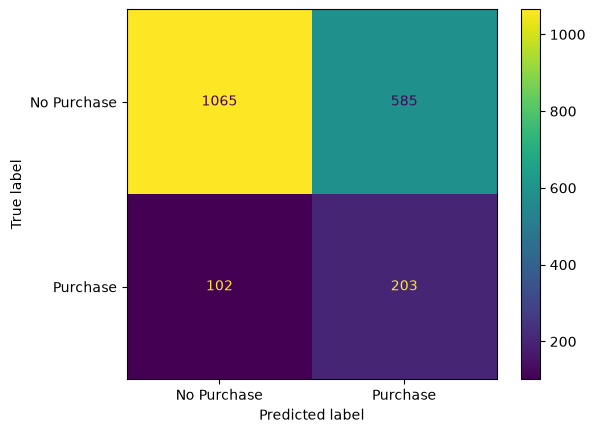

Tuned Decision Tree
Accuracy: 0.618925831202046
Precision: 0.2619047619047619
Recall: 0.7934426229508197
F1 Score: 0.3938161106590724
ROC-AUC: 0.7457655240933931


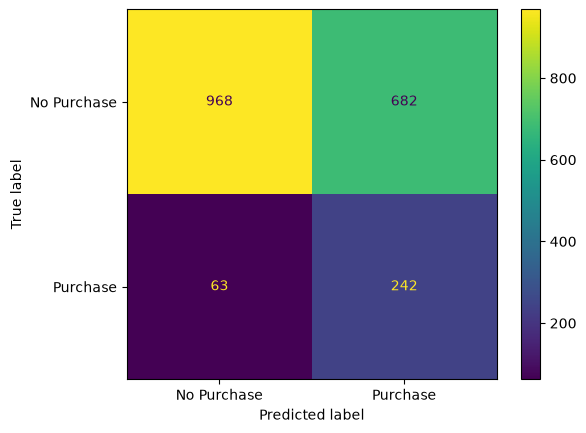

Tuned Random Forest
Accuracy: 0.7723785166240409
Precision: 0.34375
Recall: 0.5049180327868853
F1 Score: 0.40903054448871184
ROC-AUC: 0.7569995032290114


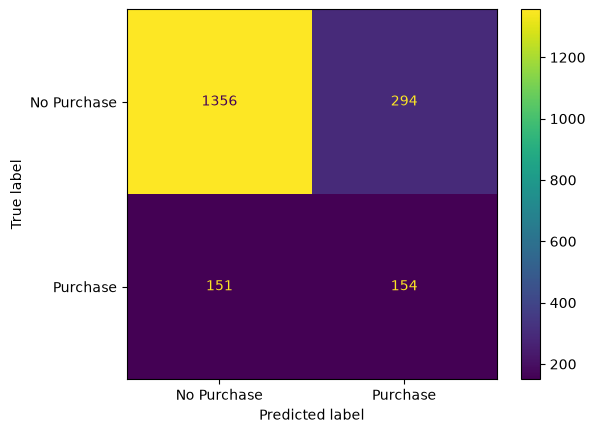

In [36]:
tuned_models = {
    "Tuned Logistic Regression": logistic_search.best_estimator_,
    "Tuned Decision Tree": decision_search.best_estimator_,
    "Tuned Random Forest": forest_search.best_estimator_
}

tuned_results = {}

for name, model in tuned_models.items():
    print(name)
    tuned_results[name] = evaluate_model(model, X_test, y_test)

## 9. Compare the original and tuned models


In [37]:
initial_df = pd.DataFrame(initial_results).T
initial_df["Model"] = initial_df.index

tuned_df = pd.DataFrame(tuned_results).T
tuned_df["Model"] = tuned_df.index

comparison = pd.concat([initial_df, tuned_df])

comparison = comparison.reset_index(drop=True)

print(comparison)

   Accuracy  Precision    Recall  F1-score   ROC-AUC  \
0  0.841944   0.409091  0.029508  0.055046  0.722098   
1  0.760614   0.271709  0.318033  0.293051  0.580229   
2  0.840921   0.459459  0.111475  0.179420  0.741976   
3  0.648593   0.257614  0.665574  0.371455  0.721850   
4  0.618926   0.261905  0.793443  0.393816  0.745766   
5  0.772379   0.343750  0.504918  0.409031  0.757000   

                       Model  
0        Logistic Regression  
1              Decision Tree  
2              Random Forest  
3  Tuned Logistic Regression  
4        Tuned Decision Tree  
5        Tuned Random Forest  


## 10. Compare cross-validation and test F1-scores


In [38]:
cv_comparison = pd.DataFrame({
    "Model": list(cv_results.keys()),
    "Initial CV F1-score": [scores.mean() for scores in cv_results.values()]
})

cv_comparison = cv_comparison.merge(
    initial_df[["Model", "F1-score"]],
    on="Model"
)

cv_comparison = cv_comparison.rename(columns={"F1-score": "Initial Test F1-score"})

tuned_cv = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree", "Random Forest"],
    "Tuned CV F1-score": [logistic_search.best_score_, decision_search.best_score_, forest_search.best_score_]
})

cv_comparison = cv_comparison.merge(tuned_cv, on="Model", how="left")

print(cv_comparison.round(4).to_string(index=False))

              Model  Initial CV F1-score  Initial Test F1-score  Tuned CV F1-score
Logistic Regression               0.0585                 0.0550             0.3925
      Decision Tree               0.3048                 0.2931             0.3899
      Random Forest               0.1954                 0.1794             0.4322


## 11. Model Comparison chart


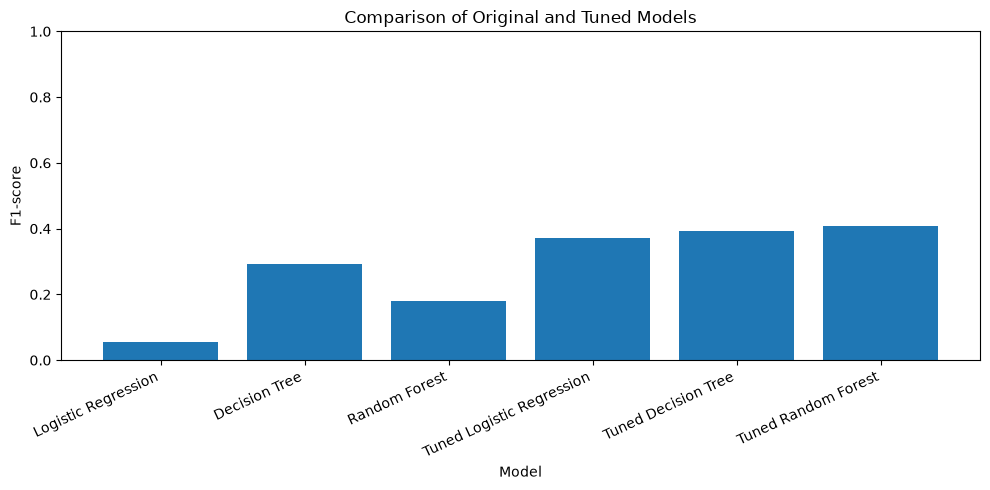

In [39]:
plt.figure(figsize=(10, 5))
plt.bar(comparison["Model"], comparison["F1-score"])
plt.ylabel("F1-score")
plt.xlabel("Model")
plt.title("Comparison of Original and Tuned Models")
plt.ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 12. Save tuned models and results


In [40]:
results_path = Path("data/processed/tuned_models.joblib")

final_data = {
    "best_logistic": logistic_search.best_estimator_,
    "best_forest": forest_search.best_estimator_,
    "best_decision_tree": decision_search.best_estimator_,
    "logistic_best_parameters": logistic_search.best_params_,
    "forest_best_parameters": forest_search.best_params_,
    "decision_tree_best_parameters": decision_search.best_params_,
    "initial_results": initial_results,
    "tuned_results": tuned_results,
    "comparison": comparison,
    "cross_validation_comparison": cv_comparison
}

joblib.dump(final_data, results_path)

print("Tuned models and evaluation results saved successfully.")

Tuned models and evaluation results saved successfully.
